# Online News Popularity: Drivers of Article Shares

**Questions**
1. Which article characteristics are associated with more shares, holding everything else constant?
2. Can we predict whether an article will be popular (more than 1,400 shares, roughly the median)?
3. Does the headline text add predictive signal beyond the structured features?

**Data:** UCI / Kaggle *Online News Popularity*: 39,644 Mashable articles (2013–2014), 58 predictive features covering content, links, media, keywords, publishing day, channel, LDA topics and sentiment, plus the URL and share count.

**Approach:** EDA, then OLS regression with controls for driver analysis, then classification (baseline, logistic regression, gradient boosting), then a headline-text experiment using TF-IDF features from the URL slug.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from scipy.sparse import hstack, csr_matrix

df = pd.read_csv('data/OnlineNewsPopularity.csv')
df.columns = df.columns.str.strip()
print('Shape:', df.shape)
print('Missing values:', df.isna().sum().sum())
print(df['shares'].describe().round(0).to_string())

Shape: (39644, 61)
Missing values: 0
count     39644.0
mean       3395.0
std       11627.0
min           1.0
25%         946.0
50%        1400.0
75%        2800.0
max      843300.0


## Exploratory analysis

Skewness of shares: 34.0
channel
world            1100.0
entertainment    1200.0
bus              1400.0
lifestyle        1700.0
tech             1700.0
other            1900.0
socmed           2100.0
weekday
monday       1400.0
tuesday      1300.0
wednesday    1300.0
thursday     1400.0
friday       1500.0
saturday     2000.0
sunday       1900.0


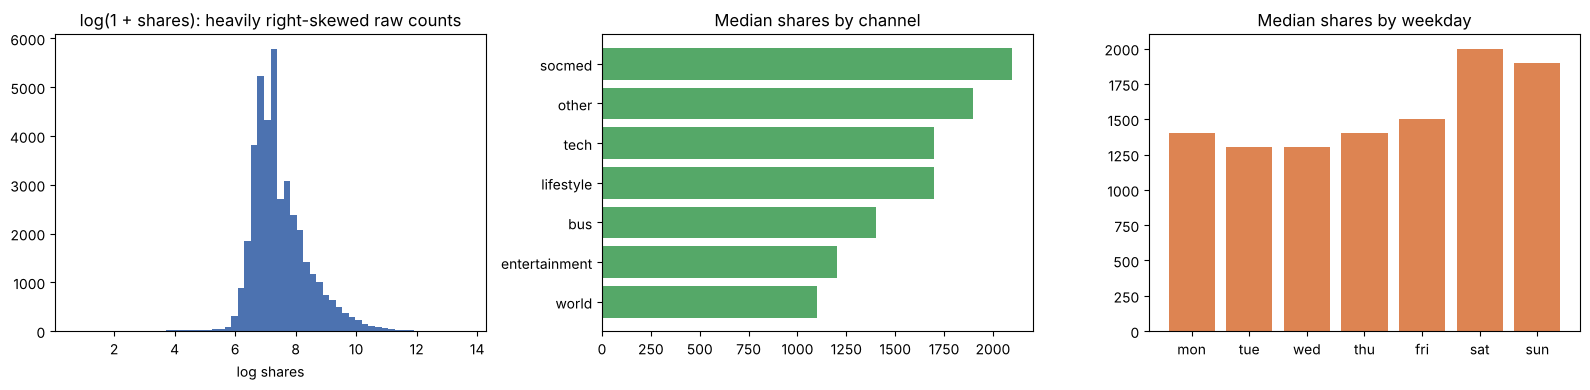

In [2]:
channel_cols = [c for c in df.columns if c.startswith('data_channel_is_')]
day_cols = [c for c in df.columns if c.startswith('weekday_is_')]
df['channel'] = df[channel_cols].idxmax(axis=1).str.replace('data_channel_is_', '')
df.loc[df[channel_cols].sum(axis=1) == 0, 'channel'] = 'other'
df['weekday'] = df[day_cols].idxmax(axis=1).str.replace('weekday_is_', '')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(np.log1p(df['shares']), bins=60, color='#4C72B0')
axes[0].set_title('log(1 + shares): heavily right-skewed raw counts'); axes[0].set_xlabel('log shares')

by_ch = df.groupby('channel')['shares'].median().sort_values()
axes[1].barh(by_ch.index, by_ch.values, color='#55A868'); axes[1].set_title('Median shares by channel')

order = ['monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday']
by_day = df.groupby('weekday')['shares'].median().reindex(order)
axes[2].bar([d[:3] for d in order], by_day.values, color='#DD8452'); axes[2].set_title('Median shares by weekday')
plt.tight_layout()
print('Skewness of shares:', round(df['shares'].skew(), 1))
print(by_ch.to_string()); print(by_day.to_string())

## 1. Driver analysis: OLS regression with controls
Outcome: `log(1 + shares)` (raw shares are extremely skewed). All features enter together, so each coefficient is the association with shares **holding the other features constant**. Redundant columns are dropped to avoid perfect collinearity: `is_weekend` (duplicates Sat/Sun dummies), `weekday_is_sunday` (reference day), `LDA_04` (topic shares sum to 1). Features are standardised so coefficients are comparable: the effect of a one-standard-deviation change.

In [3]:
drop = ['url', 'timedelta', 'shares', 'channel', 'weekday', 'is_weekend', 'weekday_is_sunday', 'LDA_04']
Xo = df.drop(columns=drop)
binary = [c for c in Xo.columns if set(Xo[c].unique()) <= {0, 1}]
Xs = Xo.copy()
cont = [c for c in Xo.columns if c not in binary]
Xs[cont] = (Xo[cont] - Xo[cont].mean()) / Xo[cont].std()
yo = np.log1p(df['shares']).values

A = np.column_stack([np.ones(len(Xs)), Xs.values])
beta, *_ = np.linalg.lstsq(A, yo, rcond=None)
resid = yo - A @ beta
n, k = A.shape
sigma2 = resid @ resid / (n - k)
se = np.sqrt(np.diag(sigma2 * np.linalg.pinv(A.T @ A)))
ols = pd.DataFrame({'coef': beta, 'std_err': se, 't': beta / se}, index=['const'] + list(Xs.columns))
r2 = 1 - resid @ resid / ((yo - yo.mean()) @ (yo - yo.mean()))
print(f'n = {n}, features = {k-1}, R-squared = {r2:.3f}')
print('\nStrongest significant associations (|t| > 3), sorted by coefficient:')
sig = ols.drop('const').query('abs(t) > 3').sort_values('coef')
print(sig.round(3).to_string())

n = 39644, features = 55, R-squared = 0.127

Strongest significant associations (|t| > 3), sorted by coefficient:
                                coef  std_err       t
weekday_is_tuesday            -0.286    0.020 -14.604
weekday_is_wednesday          -0.282    0.020 -14.412
weekday_is_thursday           -0.277    0.020 -14.110
kw_max_avg                    -0.255    0.012 -21.829
weekday_is_monday             -0.219    0.020 -11.001
weekday_is_friday             -0.214    0.020 -10.504
data_channel_is_entertainment -0.183    0.019  -9.507
data_channel_is_bus           -0.166    0.029  -5.741
data_channel_is_lifestyle     -0.106    0.030  -3.540
average_token_length          -0.079    0.015  -5.164
kw_avg_min                    -0.076    0.014  -5.244
LDA_02                        -0.066    0.010  -6.774
kw_min_avg                    -0.057    0.007  -8.837
kw_avg_max                    -0.043    0.008  -5.025
LDA_03                        -0.037    0.011  -3.461
LDA_01                

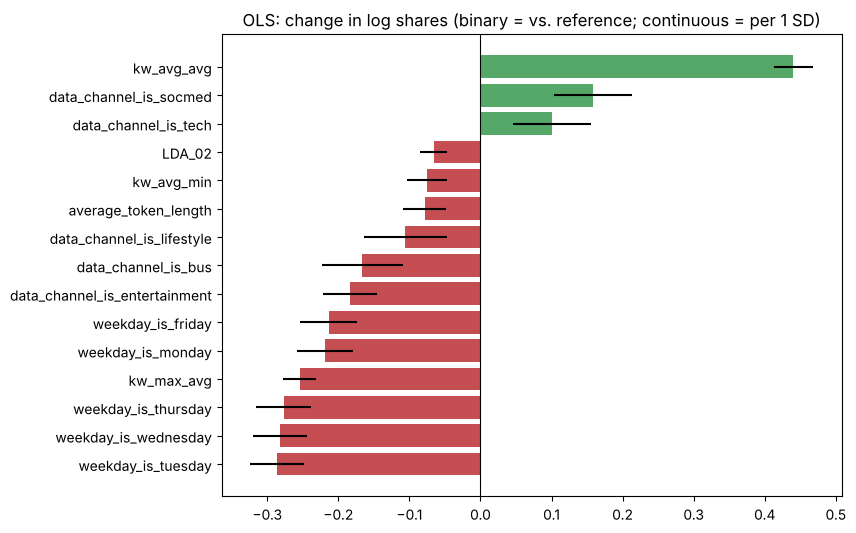

In [4]:
top = sig.reindex(sig['coef'].abs().sort_values(ascending=False).index).head(15).sort_values('coef')
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top['coef'], xerr=1.96 * top['std_err'],
        color=np.where(top['coef'] > 0, '#55A868', '#C44E52'))
ax.axvline(0, color='k', lw=0.8)
ax.set_title('OLS: change in log shares (binary = vs. reference; continuous = per 1 SD)')

## 2. Predicting popularity
Target: popular = shares > 1,400 (49% of articles). Stratified 80/20 split.

In [5]:
df['slug'] = (df['url'].str.rstrip('/').str.split('/').str[-1]
              .str.replace(r'-\d+$', '', regex=True).str.replace('-', ' '))
y = (df['shares'] > 1400).astype(int)
X = df.drop(columns=['url', 'timedelta', 'shares', 'slug', 'channel', 'weekday'])
print('Popular share:', round(y.mean(), 3), '| features:', X.shape[1])

X_train, X_test, y_train, y_test, s_train, s_test = train_test_split(
    X, y, df['slug'], test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
N_train, N_test = scaler.transform(X_train), scaler.transform(X_test)

results, probas = [], {}
def record(name, pred, proba):
    probas[name] = proba
    results.append({'Model': name, 'Accuracy': accuracy_score(y_test, pred), 'ROC-AUC': roc_auc_score(y_test, proba)})

base = DummyClassifier().fit(X_train, y_train)
record('Majority-class baseline', base.predict(X_test), np.full(len(y_test), 0.5))

logreg = LogisticRegression(max_iter=3000).fit(N_train, y_train)
record('Logistic Regression (numeric features)', logreg.predict(N_test), logreg.predict_proba(N_test)[:, 1])

gb = HistGradientBoostingClassifier(max_iter=600, learning_rate=0.03, random_state=0).fit(X_train, y_train)
record('Gradient Boosting (numeric features)', gb.predict(X_test), gb.predict_proba(X_test)[:, 1])
print(pd.DataFrame(results).set_index('Model').round(3).to_string())

Popular share: 0.493 | features: 58
                                        Accuracy  ROC-AUC
Model                                                    
Majority-class baseline                    0.507    0.500
Logistic Regression (numeric features)     0.651    0.701
Gradient Boosting (numeric features)       0.664    0.728


## 3. Does headline text help?
The dataset has no article text, but each URL contains the headline as a slug, e.g. `amazon-instant-video-browser`. Headlines are embedded with TF-IDF (unigrams and bigrams) and tested three ways: text alone, text + numeric features in logistic regression, and an out-of-fold headline score added to gradient boosting (out-of-fold to avoid leakage).

In [6]:
print('Example headlines:', s_train.head(3).tolist())
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True).fit(s_train)
T_train, T_test = tfidf.transform(s_train), tfidf.transform(s_test)
print('TF-IDF vocabulary size:', len(tfidf.vocabulary_))

text_lr = LogisticRegression(max_iter=3000).fit(T_train, y_train)
record('Headline TF-IDF only', text_lr.predict(T_test), text_lr.predict_proba(T_test)[:, 1])

C_train = hstack([csr_matrix(N_train), T_train]).tocsr()
C_test = hstack([csr_matrix(N_test), T_test]).tocsr()
combo = LogisticRegression(max_iter=5000, C=0.5).fit(C_train, y_train)
record('Logistic Regression (numeric + headline TF-IDF)', combo.predict(C_test), combo.predict_proba(C_test)[:, 1])

oof = cross_val_predict(LogisticRegression(max_iter=3000), T_train, y_train, cv=5, method='predict_proba')[:, 1]
gb_text = HistGradientBoostingClassifier(max_iter=600, learning_rate=0.03, random_state=0).fit(
    X_train.assign(headline_score=oof), y_train)
Xt = X_test.assign(headline_score=text_lr.predict_proba(T_test)[:, 1])
record('Gradient Boosting (numeric + headline score)', gb_text.predict(Xt), gb_text.predict_proba(Xt)[:, 1])

summary = pd.DataFrame(results).set_index('Model').round(3)
print(summary.to_string())

Example headlines: ['nexus manual brief', 'bump file transfer', 'thousands from iraq minority flee to syria']
TF-IDF vocabulary size: 9918
                                                 Accuracy  ROC-AUC
Model                                                             
Majority-class baseline                             0.507    0.500
Logistic Regression (numeric features)              0.651    0.701
Gradient Boosting (numeric features)                0.664    0.728
Headline TF-IDF only                                0.519    0.526
Logistic Regression (numeric + headline TF-IDF)     0.642    0.693
Gradient Boosting (numeric + headline score)        0.667    0.728


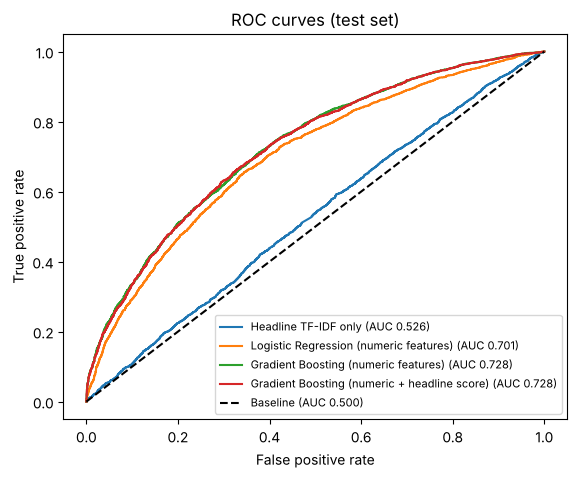

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for name in ['Headline TF-IDF only', 'Logistic Regression (numeric features)',
             'Gradient Boosting (numeric features)', 'Gradient Boosting (numeric + headline score)']:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC {summary.loc[name, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], 'k--', label='Baseline (AUC 0.500)')
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_title('ROC curves (test set)')
ax.legend(fontsize=8)

kw_avg_avg                       0.0273
is_weekend                       0.0184
self_reference_min_shares        0.0115
data_channel_is_entertainment    0.0076
kw_max_max                       0.0067
data_channel_is_tech             0.0064
kw_min_avg                       0.0057
data_channel_is_socmed           0.0054
LDA_00                           0.0052
kw_min_max                       0.0051
kw_max_avg                       0.0050
num_imgs                         0.0035
kw_avg_max                       0.0026
num_hrefs                        0.0026
n_unique_tokens                  0.0025


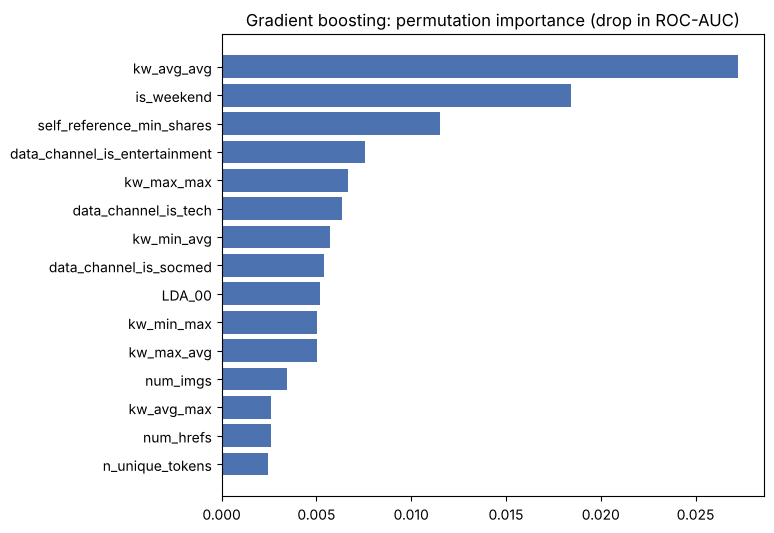

In [8]:
imp = permutation_importance(gb, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=0)
imp = pd.Series(imp.importances_mean, index=X_test.columns).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(imp.index, imp.values, color='#4C72B0')
ax.set_title('Gradient boosting: permutation importance (drop in ROC-AUC)')
print(imp.sort_values(ascending=False).round(4).to_string())

## Results and conclusions

**Prediction (popular = more than 1,400 shares, test set of 7,929 articles)**

| Model | Accuracy | ROC-AUC |
|---|---|---|
| Majority-class baseline | 0.507 | 0.500 |
| Logistic Regression (numeric features) | 0.651 | 0.701 |
| **Gradient Boosting (numeric features)** | **0.664** | **0.728** |
| Headline TF-IDF only | 0.519 | 0.526 |
| Gradient Boosting + headline score | 0.667 | 0.728 |

1. **Modeling choice drove the gain:** gradient boosting lifted accuracy from a 0.51 baseline to 0.66 and ROC-AUC from 0.50 to 0.73, beating logistic regression (0.70 AUC) by capturing non-linear effects.
2. **Headline text added no signal:** TF-IDF on headlines alone barely beats chance (AUC 0.53), and adding it to the structured features left ROC-AUC unchanged (0.728 → 0.728). Popularity here depends far more on topic, keyword and timing context than on headline wording.
3. **Drivers (OLS with controls, log shares, R² = 0.13):**
   - **Keyword strength** is the largest effect: articles whose keywords historically earn more shares (`kw_avg_avg`) get substantially more shares.
   - **Weekend publishing helps:** compared with Sunday, articles published Monday–Friday get roughly 20–25% fewer shares (coefficients −0.21 to −0.29 on log shares); Saturday and Sunday medians are about 1,900–2,000 vs. 1,300–1,500 on weekdays.
   - **Channel matters:** Social Media and Tech articles earn more shares than uncategorised articles; Entertainment, Business and World earn fewer.
   - More links, images and keywords, and more subjective writing, are modestly positive.
4. Permutation importance for gradient boosting tells the same story: keyword strength, weekend publishing, self-referenced article shares and channel are the most useful features.